In [1]:
# Download the MovieLens 100K dataset
!wget -q https://files.grouplens.org/datasets/movielens/ml-100k.zip

# Extract the downloaded ZIP file
!unzip -qo ml-100k.zip

# Show the extracted files
!ls ml-100k

allbut.pl  u1.base  u2.test  u4.base  u5.test  ub.base	u.genre  u.occupation
mku.sh	   u1.test  u3.base  u4.test  ua.base  ub.test	u.info	 u.user
README	   u2.base  u3.test  u5.base  ua.test  u.data	u.item


In [2]:
import pandas as pd

In [3]:
# Define the movie genre columns
genre_columns = [
    "unknown", "Action", "Adventure", "Animation",
    "Children", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

# Define all movie columns
movie_columns = [
    "movie_id", "title", "release_date",
    "video_release_date", "imdb_url"
] + genre_columns

# Read the movie file
movies = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    names=movie_columns
)

# Display the first five movies
movies.head()

,movie_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [4]:
movies.columns

Index(['movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url',
       'unknown', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy',
       'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror',
       'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War',
       'Western'],
      dtype='object')

In [5]:
# How many movies and columns do we have?
print("Dataset shape:", movies.shape)

# What are the column names?
print(movies.columns.tolist())

# Check for missing values
print(movies.isnull().sum())

# Check for duplicate movie IDs
print("Duplicate IDs:", movies["movie_id"].duplicated().sum())

Dataset shape: (1682, 24)
['movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url', 'unknown', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
movie_id                 0
title                    0
release_date             1
video_release_date    1682
imdb_url                 3
unknown                  0
Action                   0
Adventure                0
Animation                0
Children                 0
Comedy                   0
Crime                    0
Documentary              0
Drama                    0
Fantasy                  0
Film-Noir                0
Horror                   0
Musical                  0
Mystery                  0
Romance                  0
Sci-Fi                   0
Thriller                 0
War                      0
Western                  0
dtype: int64
Duplicate IDs: 0


In [6]:
# Select only the 19 genre columns
movie_features = movies[genre_columns]

# Display the first five rows
movie_features.head()

,unknown,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0


In [7]:
# Check the dimensions of our feature matrix
print("Feature matrix shape:", movie_features.shape)

# Display the genre features for the first movie
print(movie_features.iloc[0])

Feature matrix shape: (1682, 19)
unknown        0
Action         0
Adventure      0
Animation      1
Children       1
Comedy         1
Crime          0
Documentary    0
Drama          0
Fantasy        0
Film-Noir      0
Horror         0
Musical        0
Mystery        0
Romance        0
Sci-Fi         0
Thriller       0
War            0
Western        0
Name: 0, dtype: int64


In [8]:
# Show the genres assigned to the first five movies
for _, movie in movies.head().iterrows():

    # Find genres marked with 1
    selected_genres = [
        genre
        for genre in genre_columns
        if movie[genre] == 1
    ]

    print(movie["title"], ":", selected_genres)

Toy Story (1995) : ['Animation', 'Children', 'Comedy']
GoldenEye (1995) : ['Action', 'Adventure', 'Thriller']
Four Rooms (1995) : ['Thriller']
Get Shorty (1995) : ['Action', 'Comedy', 'Drama']
Copycat (1995) : ['Crime', 'Drama', 'Thriller']


In [9]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TOP_K = 10

print("Libraries loaded successfully")

Libraries loaded successfully


In [11]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-100k.zip
!unzip -qo ml-100k.zip

In [12]:
# Define genre names
genre_columns = [
    "unknown", "Action", "Adventure", "Animation",
    "Children", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

# Define movie columns
movie_columns = [
    "movie_id", "title", "release_date",
    "video_release_date", "imdb_url"
] + genre_columns

# Load movies
movies = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    names=movie_columns
)

# Load ratings
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)

display(movies.head())
display(ratings.head())

Movies: (1682, 24)
Ratings: (100000, 4)


,movie_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [13]:
print("Missing movie values:")
print(movies[genre_columns].isnull().sum().sum())

print("\nDuplicate movie IDs:")
print(movies["movie_id"].duplicated().sum())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nUnique users:", ratings["user_id"].nunique())
print("Unique rated movies:", ratings["movie_id"].nunique())

Missing movie values:
0

Duplicate movie IDs:
0

Rating distribution:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

Unique users: 943
Unique rated movies: 1682


In [14]:
movies = movies.drop_duplicates("movie_id").copy()

movies[genre_columns] = (
    movies[genre_columns]
    .fillna(0)
    .astype(int)
)

ratings = ratings.dropna(
    subset=["user_id", "movie_id", "rating"]
).copy()

ratings["rating"] = ratings["rating"].astype(float)

# Keep only ratings belonging to known movies
ratings = ratings[
    ratings["movie_id"].isin(movies["movie_id"])
].copy()

# Feature matrix
movie_features = movies.set_index("movie_id")[genre_columns]

print("Feature matrix:", movie_features.shape)

Feature matrix: (1682, 19)


**content-based model**

In [15]:
# Calculate similarity between every pair of movies
similarity_matrix = cosine_similarity(movie_features)

# Convert the result into a DataFrame
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=movie_features.index,
    columns=movie_features.index
)

print("Similarity matrix:", similarity_df.shape)

Similarity matrix: (1682, 1682)


**Build user preference profiles**

A user profile represents the genres that a user tends to like.

For our first implementation, we will use ratings above 3 as positive preferences and weight them by how highly the user rated the movies.

In [16]:
# Build a preference profile for each user
def build_user_profile(user_id, training_ratings):

    user_history = training_ratings[
        training_ratings["user_id"] == user_id
    ]

    # Keep positively rated movies
    liked_movies = user_history[
        user_history["rating"] > 3
    ]

    if liked_movies.empty:
        return None

    # Get genre vectors of liked movies
    features = movie_features.loc[
        liked_movies["movie_id"]
    ].values

    # Higher ratings contribute more strongly
    weights = (liked_movies["rating"].values - 3)

    # Weighted average of movie features
    profile = np.average(
        features,
        axis=0,
        weights=weights
    )

    return profile

**Generate recommendations**

The model compares the user profile against movie feature vectors and returns the highest-scoring unseen movies.

In [17]:
def recommend_movies(user_id, training_ratings, top_n=10):

    profile = build_user_profile(
        user_id,
        training_ratings
    )

    if profile is None:
        return pd.DataFrame()

    # Compare user profile with all movies
    scores = cosine_similarity(
        profile.reshape(1, -1),
        movie_features.values
    ).flatten()

    # Exclude movies already rated by the user
    watched_movies = training_ratings[
        training_ratings["user_id"] == user_id
    ]["movie_id"].tolist()

    recommendations = pd.DataFrame({
        "movie_id": movie_features.index,
        "similarity_score": scores
    })

    recommendations = recommendations[
        ~recommendations["movie_id"].isin(watched_movies)
    ]

    recommendations = recommendations.sort_values(
        "similarity_score",
        ascending=False
    ).head(top_n)

    # Add movie titles
    recommendations = recommendations.merge(
        movies[["movie_id", "title"]],
        on="movie_id"
    )

    return recommendations[
        ["movie_id", "title", "similarity_score"]
    ]

Test it using a user in the dataset

In [18]:
sample_user = ratings["user_id"].iloc[0]

recommendations = recommend_movies(
    sample_user,
    ratings,
    top_n=10
)

print("Recommendations for user:", sample_user)
display(recommendations)

Recommendations for user: 196


,movie_id,title,similarity_score
0,34,"Doom Generation, The (1995)",0.900563
1,1312,"Pompatus of Love, The (1996)",0.900563
2,964,"Month by the Lake, A (1995)",0.900563
3,953,Unstrung Heroes (1995),0.900563
4,941,With Honors (1994),0.900563
5,1588,Salut cousin! (1996),0.900563
6,1475,Bhaji on the Beach (1993),0.900563
7,1272,Talking About Sex (1994),0.900563
8,47,Ed Wood (1994),0.900563
9,65,What's Eating Gilbert Grape (1993),0.900563


**Testing and evaluation**

We must not evaluate the model using the same ratings it learned from. Otherwise, the evaluation may give misleading results.

We will divide the ratings into training and testing sets, keeping at least one training rating for each user.

**Split the dataset**


In [19]:
train_parts = []
test_parts = []

rng = np.random.default_rng(RANDOM_STATE)

for user_id, group in ratings.groupby("user_id"):

    group = group.sample(
        frac=1,
        random_state=RANDOM_STATE
    )

    # Users with only one rating cannot be split
    if len(group) < 2:
        train_parts.append(group)
        continue

    test_size = max(1, int(len(group) * 0.2))

    test_parts.append(group.iloc[:test_size])
    train_parts.append(group.iloc[test_size:])

train = pd.concat(train_parts).reset_index(drop=True)
test = pd.concat(test_parts).reset_index(drop=True)

print("Training ratings:", len(train))
print("Testing ratings:", len(test))

Training ratings: 80367
Testing ratings: 19633


**Implement evaluation metrics**

We will consider ratings of 4 or 5 as relevant preferences.

In [20]:
def precision_at_k(recommended, relevant, k=10):

    recommended = recommended[:k]

    if not recommended:
        return 0.0

    hits = len(set(recommended) & set(relevant))

    return hits / k


def recall_at_k(recommended, relevant, k=10):

    if not relevant:
        return np.nan

    hits = len(set(recommended[:k]) & set(relevant))

    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k=10):

    recommended = recommended[:k]

    relevance = [
        1 if movie in relevant else 0
        for movie in recommended
    ]

    dcg = sum(
        value / np.log2(index + 2)
        for index, value in enumerate(relevance)
    )

    ideal = sorted(relevance, reverse=True)

    idcg = sum(
        value / np.log2(index + 2)
        for index, value in enumerate(ideal)
    )

    return dcg / idcg if idcg > 0 else 0.0

**Evaluate recommendations**

In [21]:
def evaluate_model(training_ratings, testing_ratings, k=10):

    precision_scores = []
    recall_scores = []
    ndcg_scores = []

    all_recommended = set()
    all_catalog = set(movies["movie_id"])

    for user_id in testing_ratings["user_id"].unique():

        # Relevant movies in the test set
        user_test = testing_ratings[
            testing_ratings["user_id"] == user_id
        ]

        relevant = set(
            user_test[user_test["rating"] >= 4]["movie_id"]
        )

        if not relevant:
            continue

        # Generate recommendations
        recs = recommend_movies(
            user_id,
            training_ratings,
            top_n=k
        )

        recommended = recs["movie_id"].tolist()

        if not recommended:
            continue

        precision_scores.append(
            precision_at_k(recommended, relevant, k)
        )

        recall_scores.append(
            recall_at_k(recommended, relevant, k)
        )

        ndcg_scores.append(
            ndcg_at_k(recommended, relevant, k)
        )

        all_recommended.update(recommended)

    return {
        "Precision@10": np.mean(precision_scores),
        "Recall@10": np.nanmean(recall_scores),
        "NDCG@10": np.mean(ndcg_scores),
        "Catalog Coverage": len(all_recommended) / len(all_catalog),
        "Evaluated Users": len(precision_scores)
    }


results = evaluate_model(train, test)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, (int, float, np.number)) else f"{metric}: {value}")

Precision@10: 0.0222
Recall@10: 0.0218
NDCG@10: 0.0908
Catalog Coverage: 0.4946
Evaluated Users: 926.0000


**Diversity, novelty and fairness**

These metrics help establish whether the model gives useful recommendations beyond simply matching user preferences.

In [24]:
def evaluate_beyond_accuracy(training_ratings, testing_ratings, k=10):

    # Calculate movie popularity using training data only
    popularity = training_ratings["movie_id"].value_counts()

    total_ratings = len(training_ratings)

    # Define popular and less-popular movies
    median_popularity = popularity.median()

    long_tail_movies = set(
        popularity[popularity <= median_popularity].index
    )

    diversities = []
    novelties = []
    long_tail_exposure = []

    all_recommended = set()

    for user_id in testing_ratings["user_id"].unique():

        recs = recommend_movies(
            user_id,
            training_ratings,
            top_n=k
        )

        if recs.empty:
            continue

        recommended = recs["movie_id"].tolist()

        if not recommended:
            continue

        all_recommended.update(recommended)

        # Diversity: average pairwise genre distance
        vectors = movie_features.loc[recommended].values

        if len(vectors) > 1:
            similarities = cosine_similarity(vectors)
            upper = similarities[np.triu_indices(len(vectors), k=1)]
            diversities.append(1 - upper.mean())
        else:
            diversities.append(0)

        # Novelty: inverse popularity
        item_novelty = []

        for movie_id in recommended:
            count = popularity.get(movie_id, 0)
            probability = (count + 1) / (total_ratings + len(movie_features))
            item_novelty.append(-np.log2(probability))

        novelties.append(np.mean(item_novelty))

        # Long-tail exposure
        long_tail_exposure.append(
            np.mean([
                movie_id in long_tail_movies
                for movie_id in recommended
            ])
        )

    return {
        "Intra-list Diversity": np.mean(diversities),
        "Average Novelty": np.mean(novelties),
        "Long-tail Exposure": np.mean(long_tail_exposure),
        "Catalog Coverage": len(all_recommended) / len(movies)
    }


beyond_results = evaluate_beyond_accuracy(train, test)

for metric, value in beyond_results.items():
    print(f"{metric}: {value:.4f}")

Intra-list Diversity: 0.1321
Average Novelty: 11.7082
Long-tail Exposure: 0.3786
Catalog Coverage: 0.4982


**Understanding fairness:** Long-tail exposure is a useful fairness-related indicator of how much visibility less-popular movies receive. It is not a complete fairness measure. In your report, describe it as an exposure-distribution proxy, not proof that the model is fair to every user or item group.

**Visualize the results**

,Metric,Score
0,Precision@10,0.022246
1,Recall@10,0.021814
2,NDCG@10,0.090829
3,Catalog Coverage,0.498216
4,Evaluated Users,926.000000
5,Intra-list Diversity,0.132116
6,Average Novelty,11.708205
7,Long-tail Exposure,0.378556


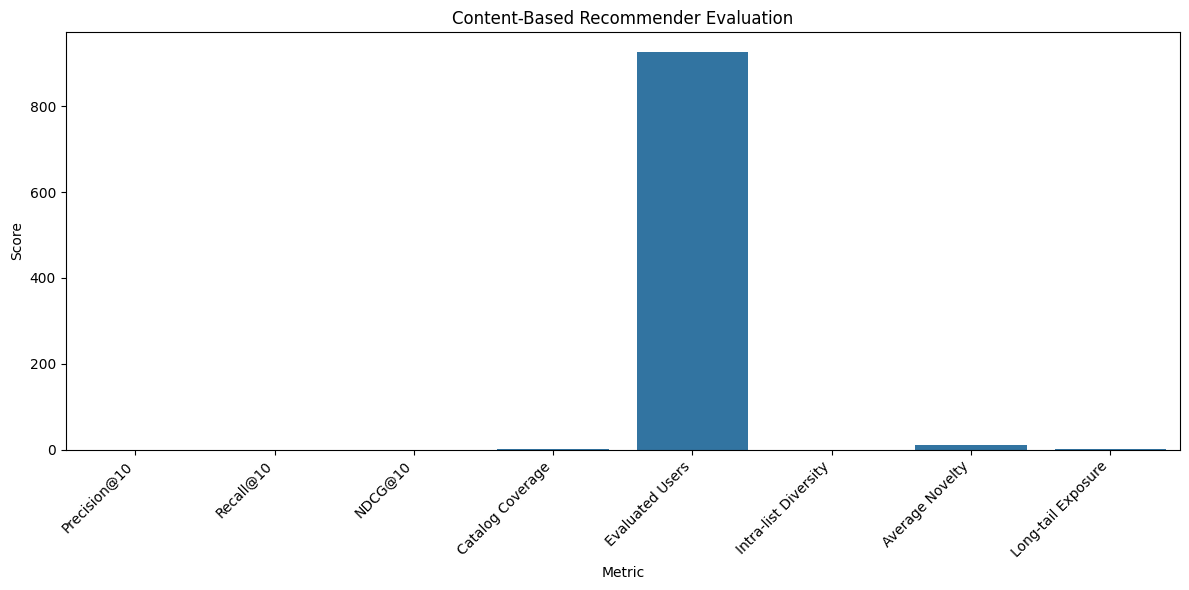

In [25]:
# Combine the evaluation results
all_results = {
    **results,
    **beyond_results
}

evaluation_df = pd.DataFrame(
    list(all_results.items()),
    columns=["Metric", "Score"]
)

display(evaluation_df)

# Plot the results
plt.figure(figsize=(12, 6))

sns.barplot(
    data=evaluation_df,
    x="Metric",
    y="Score"
)

plt.title("Content-Based Recommender Evaluation")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()